## Scaling relations in the Local Volume Database

Published measurements of nearby dwarf galaxies and star clusters, from the LVDB export.

### Setup
Paths come from `notebook_config.ini`, so the same notebook runs on archlinux and py-noether.

In [1]:
from pathlib import Path
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

from utils.loading import ROOT, CONFIG          # project root and this machine's notebook_config.ini

# LVDB export: [Data] lvdb in notebook_config.ini, relative to the project root (default LVDB/comb_all.csv).
LVDB = Path(ROOT) / CONFIG.get("Data", "lvdb", fallback="LVDB/comb_all.csv")
LVDB_URL = "https://github.com/apace7/local_volume_database/releases/download/v1.1.1/comb_all.csv"
if not LVDB.exists():                           # first run on a machine: fetch the pinned release
    LVDB.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(LVDB_URL, LVDB)
ROWS, COLS = 1727, 122                          # the export version this notebook was written against
print(LVDB)

/home/edge/data/B8_MolecularGas/LVDB/comb_all.csv


Constants: the file's V-to-mass conversion, family colours, named objects.

In [2]:
# The file's own V-band light to stellar mass conversion: log10(M*/Msun) = MASS_OFFSET - 0.4 M_V.
MASS_OFFSET = 2.234

# One Okabe-Ito colour per dwarf family, and the dwarf_* table names mapped onto those labels.
FAMILIES = {"Milky Way satellite": "#0072B2", "M31 satellite": "#E69F00",
            "Local Field": "#009E73", "Local Field, distant": "#CC79A7"}
FAMILY_OF = {"dwarf_mw": "Milky Way satellite", "dwarf_m31": "M31 satellite",
             "dwarf_local_field": "Local Field", "dwarf_local_field_distant": "Local Field, distant"}

# Marked by name: LMC and SMC (best data), Leo P (closest analogue of 605), NGC 6822 (closest non-satellite).
ANCHORS = {"lmc": "LMC", "smc": "SMC", "leo_p": "Leo P", "ngc_6822": "NGC 6822"}

Plot helpers.

In [3]:
def mass_axis(ax):
    """Top axis: the stellar mass the file assigns to each V magnitude."""
    top = ax.secondary_xaxis("top", functions=(lambda mv: MASS_OFFSET - 0.4 * mv,
                                              lambda lm: (MASS_OFFSET - lm) / 0.4))
    top.set_xlabel(r"$\log_{10}(M_\star/M_\odot) = 2.234 - 0.4\,M_V$")


def split_by_error(rows, lo, hi):
    """Rows the file quotes a 1σ for, and rows it does not."""
    quoted = rows[lo].notna() & rows[hi].notna()
    return rows[quoted], rows[~quoted]


def errors(frame, lo, hi):
    """The two 1σ columns as the (2, n) array matplotlib's yerr takes."""
    return frame[[lo, hi]].to_numpy().T


def open_marker(ax, label="hollow: no 1σ quoted in the file"):
    """Legend entry for the hollow markers; returned so the legend keeps a fixed order."""
    return ax.plot([], [], marker="o", ms=5.5, mfc="none", mec="0.35", mew=0.9, ls="none", label=label)[0]


def mark_anchors(ax, rows, ycol, label="named object (counted in its family)"):
    """White star and name for each object in ANCHORS that carries the plotted quantity."""
    proxy = None
    xy = rows[["M_V", ycol]].to_numpy(float)
    pixels = ax.transData.transform(xy[np.isfinite(xy).all(axis=1)])
    # Three rings of candidate label positions, 12 angles each; keep the one furthest from any point.
    steps = [radius * np.array([np.cos(a), np.sin(a)]) for radius in (26, 44, 66)
             for a in np.arange(12) * np.pi / 6]
    for key, name in ANCHORS.items():
        hit = rows[rows.key == key]
        if hit.empty or not np.isfinite(hit[ycol].iloc[0]):
            continue
        x, y = hit.M_V.iloc[0], hit[ycol].iloc[0]
        centre = ax.transData.transform((x, y))
        clear = [np.hypot(*(pixels - (centre + s)).T).min() if ax.bbox.contains(*(centre + s)) else -1.0
                 for s in steps]
        step = steps[int(np.argmax(clear))]
        if proxy is None:
            proxy = ax.plot([], [], marker="*", ms=14, mfc="white", mec="black", mew=0.8, ls="none",
                            label=label)[0]
        ax.plot(x, y, marker="*", ms=16, mfc="white", mec="black", mew=0.8, ls="none", zorder=5)
        # Leader line only when the label lands far from its marker.
        ax.annotate(name, (x, y), textcoords="offset points", xytext=tuple(step * 72 / ax.figure.dpi),
                    fontsize=9, zorder=6, ha="center", va="center",
                    arrowprops=dict(arrowstyle="-", color="0.45", lw=0.6, shrinkA=0, shrinkB=4)
                    if np.hypot(*step) > 44 else None)
    return proxy

## 1. What the file holds

In [4]:
# Read the export and check it is the version this notebook was written against.
df = pd.read_csv(LVDB, low_memory=False)
assert df.shape == (ROWS, COLS), f"expected {ROWS} rows and {COLS} columns, found {df.shape}"
print(f"{len(df):,} objects, {df.shape[1]} columns from {LVDB}")
print(df.table.value_counts().to_string())

1,727 objects, 122 columns from /home/edge/data/B8_MolecularGas/LVDB/comb_all.csv
table
dwarf_local_field_distant    736
gc_dwarf_hosted              313
candidate                    214
gc_harris                    155
dwarf_mw                      68
dwarf_local_field             64
gc_mw_new                     58
misc                          47
dwarf_m31                     43
gc_ambiguous                  22
gc_other                       7


## 2. The dwarf-galaxy sample

In [5]:
# Keep the dwarf galaxies: the four dwarf_* families, clusters and candidates dropped.
dwarfs = df[df.table.str.startswith("dwarf")].copy()
dwarfs["family"] = dwarfs.table.map(FAMILY_OF)
assert dwarfs.family.notna().all(), dwarfs.table.unique()

print(f"{len(dwarfs)} dwarfs: " + ", ".join(f"{fam} {n}" for fam, n in dwarfs.family.value_counts().items()))
print(f"assigned a host other than the Milky Way or M31: {dwarfs.host.notna().sum() - dwarfs.host.isin(['mw', 'm_031']).sum()}")

911 dwarfs: Local Field, distant 736, Milky Way satellite 68, Local Field 64, M31 satellite 43
assigned a host other than the Milky Way or M31: 590


Rows measured per plotted quantity.

In [6]:
# How many rows each quantity plotted below is actually measured on.
for column in ["M_V", "rhalf_sph_physical", "metallicity_spectroscopic", "metallicity_isochrone", "mass_HI", "mass_HI_ul"]:
    print(f"  {column:26s} {dwarfs[column].notna().sum():4d} rows")

  M_V                         906 rows
  rhalf_sph_physical          744 rows
  metallicity_spectroscopic   115 rows
  metallicity_isochrone        65 rows
  mass_HI                     311 rows
  mass_HI_ul                  130 rows


## 3. Spectroscopic [Fe/H] against luminosity

Sample and fit.

In [7]:
# Spectroscopic [Fe/H] against M_V. The method is not the same in every family, so the scatter is larger
# than any one source quotes; the line is a single regression over all of them.
spec = dwarfs[dwarfs.metallicity_spectroscopic.notna()]
_, hollow_spec = split_by_error(spec, "metallicity_spectroscopic_em", "metallicity_spectroscopic_ep")
fit = linregress(spec.M_V, spec.metallicity_spectroscopic)

Figure.

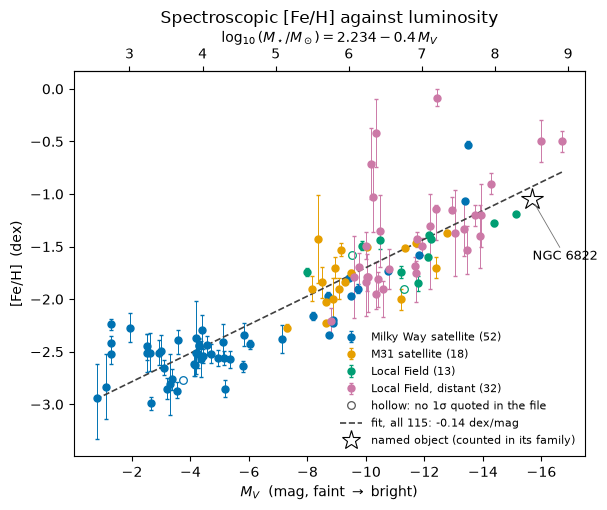

In [8]:
fig, ax = plt.subplots(figsize=(6.6, 5.0))
labelled = {}
for family, colour in FAMILIES.items():
    s = spec[spec.family == family]
    if s.empty:
        continue
    quoted, unquoted = split_by_error(s, "metallicity_spectroscopic_em", "metallicity_spectroscopic_ep")
    labelled[family] = ax.errorbar(quoted.M_V, quoted.metallicity_spectroscopic,
                                   yerr=errors(quoted, "metallicity_spectroscopic_em", "metallicity_spectroscopic_ep"),
                                   fmt="o", ms=5, lw=0, elinewidth=0.7, capsize=1.5, color=colour,
                                   label=f"{family} ({len(s)})")
    ax.plot(unquoted.M_V, unquoted.metallicity_spectroscopic, marker="o", ms=5.5, mfc="none", mec=colour,
            mew=0.9, ls="none")
labelled["hollow"] = open_marker(ax)
xs = np.array([spec.M_V.min(), spec.M_V.max()])
labelled["fit"] = ax.plot(xs, fit.intercept + fit.slope * xs, color="0.25", lw=1.2,
                          label=f"fit, all {len(spec)}: {fit.slope:.2f} dex/mag", ls="--")[0]
ax.invert_xaxis()                       # faint left, bright right
labelled["named"] = mark_anchors(ax, spec, "metallicity_spectroscopic")
ax.set_xlabel(r"$M_V$  (mag, faint $\rightarrow$ bright)")
ax.set_ylabel(r"[Fe/H]  (dex)")
ax.set_title("Spectroscopic [Fe/H] against luminosity")
mass_axis(ax)
ax.legend(handles=[h for h in labelled.values() if h is not None], fontsize=8, frameon=False)
plt.show()

Numbers; Milky Way satellites alone.

In [9]:
# Numbers, then the same fit on the Milky Way satellites alone.
resid = spec.metallicity_spectroscopic - (fit.intercept + fit.slope * spec.M_V)
print(f"{len(spec)} objects, {len(hollow_spec)} of them with no quoted 1σ (hollow)")
print(f"all {len(spec)}: slope {fit.slope:.3f} dex/mag, scatter about the fit {resid.std(ddof=2):.3f} dex")
mw = spec[spec.family == "Milky Way satellite"]
mw_fit = linregress(mw.M_V, mw.metallicity_spectroscopic)
mw_resid = mw.metallicity_spectroscopic - (mw_fit.intercept + mw_fit.slope * mw.M_V)
print(f"Milky Way satellites alone ({len(mw)}): slope {mw_fit.slope:.3f} dex/mag, scatter {mw_resid.std(ddof=2):.3f} dex")
# TODO: bands of ±1σ and ±2σ about the fit, to flag the points that sit far off it.

115 objects, 3 of them with no quoted 1σ (hollow)
all 115: slope -0.136 dex/mag, scatter about the fit 0.308 dex
Milky Way satellites alone (52): slope -0.116 dex/mag, scatter 0.254 dex


## 4. Isochrone [Fe/H], and the two methods on the same objects

Sample and fit.

In [10]:
# The file's second abundance column: isochrone fits to colour-magnitude diagrams, mostly on the Local Field
# families. Both fitted lines are drawn over the luminosity range the two samples share.
iso = dwarfs[dwarfs.metallicity_isochrone.notna()]
_, hollow_iso = split_by_error(iso, "metallicity_isochrone_em", "metallicity_isochrone_ep")
spec_fit = fit                          # the spectroscopic fit from the cell above
iso_fit = linregress(iso.M_V, iso.metallicity_isochrone)
lo, hi = max(spec.M_V.min(), iso.M_V.min()), min(spec.M_V.max(), iso.M_V.max())

Figure.

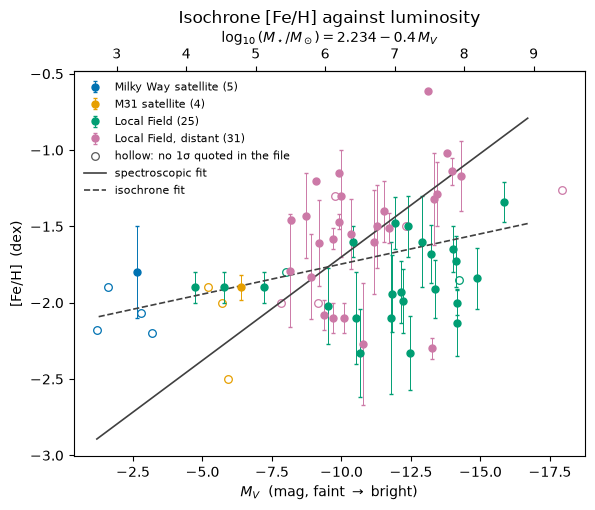

In [11]:
fig, ax = plt.subplots(figsize=(6.6, 5.0))
labelled = {}
for family, colour in FAMILIES.items():
    s = iso[iso.family == family]
    if s.empty:
        continue
    quoted, unquoted = split_by_error(s, "metallicity_isochrone_em", "metallicity_isochrone_ep")
    labelled[family] = ax.errorbar(quoted.M_V, quoted.metallicity_isochrone,
                                   yerr=errors(quoted, "metallicity_isochrone_em", "metallicity_isochrone_ep"),
                                   fmt="o", ms=5, lw=0, elinewidth=0.7, capsize=1.5, color=colour,
                                   label=f"{family} ({len(s)})")
    ax.plot(unquoted.M_V, unquoted.metallicity_isochrone, marker="o", ms=5.5, mfc="none", mec=colour,
            mew=0.9, ls="none")
labelled["hollow"] = open_marker(ax)
for name, f in [("spectroscopic", spec_fit), ("isochrone", iso_fit)]:
    labelled[name] = ax.plot([lo, hi], f.intercept + f.slope * np.array([lo, hi]),
                             "--" if name == "isochrone" else "-", color="0.25", lw=1.2,
                             label=f"{name} fit")[0]
ax.invert_xaxis()
ax.set_xlabel(r"$M_V$  (mag, faint $\rightarrow$ bright)")
ax.set_ylabel(r"[Fe/H]  (dex)")
ax.set_title("Isochrone [Fe/H] against luminosity")
mass_axis(ax)
ax.legend(handles=list(labelled.values()), fontsize=8, frameon=False)
plt.show()

Numbers; the objects with both measurements.

In [12]:
# Numbers, then the objects that carry both measurements.
iso_resid = iso.metallicity_isochrone - (iso_fit.intercept + iso_fit.slope * iso.M_V)
print(f"{len(iso)} objects, {len(hollow_iso)} of them with no quoted 1σ (hollow)")
print(f"isochrone, {len(iso)} objects: slope {iso_fit.slope:.3f} dex/mag, scatter {iso_resid.std(ddof=2):.3f} dex")
print(f"at M_V = -8, which both samples reach: spectroscopic {spec_fit.intercept + spec_fit.slope * -8:.2f} dex,"
      f" isochrone {iso_fit.intercept + iso_fit.slope * -8:.2f} dex")
both = dwarfs[["name", "M_V", "metallicity_spectroscopic", "metallicity_isochrone"]].dropna()
both = both.assign(difference=both.metallicity_isochrone - both.metallicity_spectroscopic)
print(both.to_string(index=False))
print(f"the {len(both)} objects carrying both: isochrone minus spectroscopic {both.difference.mean():+.2f} dex on average,"
      f" from {both.difference.min():+.2f} to {both.difference.max():+.2f}")

65 objects, 14 of them with no quoted 1σ (hollow)
isochrone, 65 objects: slope -0.040 dex/mag, scatter 0.349 dex
at M_V = -8, which both samples reach: spectroscopic -1.97 dex, isochrone -1.83 dex
            name    M_V  metallicity_spectroscopic  metallicity_isochrone  difference
        Bootes V  -3.20                      -2.85                  -2.20        0.65
       Pictor II  -2.65                      -2.99                  -1.80        1.19
Sagittarius dIrr -11.79                      -1.85                  -2.10       -0.25
       dw1335-29 -10.00                      -1.49                  -1.30        0.19
       dw1340-30 -10.79                      -1.71                  -2.27       -0.56
          KDG 64 -13.34                      -1.33                  -1.32        0.01
the 6 objects carrying both: isochrone minus spectroscopic +0.20 dex on average, from -0.56 to +1.19


The two methods agree in sign and in the mean but not object by object, so the two columns are kept apart
here rather than averaged: at M_V = -8 the fits differ by 0.14 dex, while the objects carrying both
differ by up to 1.2 dex. The choice of abundance measurement moves a dwarf further than feedback does
(Rey et al. 2025); every use of either column has to quote its sample size.

## 5. Size against luminosity

Sample and fit.

In [13]:
# Size against luminosity, with the spherical-equivalent half-light radius. The file's own rhalf_physical is
# the elliptical radius; the two differ by more than 10% on 321 of the 744 rows, so the choice matters here.
size = dwarfs[dwarfs.rhalf_sph_physical.notna()]
quoted_size, hollow_size = split_by_error(size, "rhalf_sph_physical_em", "rhalf_sph_physical_ep")
size_fit = linregress(size.M_V, np.log10(size.rhalf_sph_physical))

Figure.

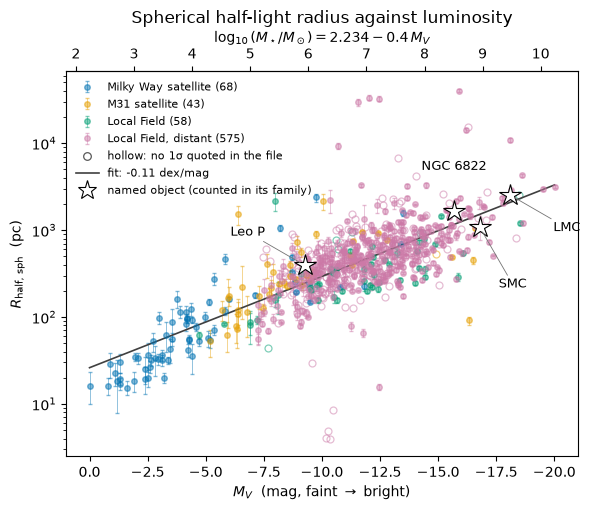

In [14]:
fig, ax = plt.subplots(figsize=(6.6, 5.0))
labelled = {}
for family, colour in FAMILIES.items():
    s = size[size.family == family]
    if s.empty:
        continue
    quoted, unquoted = split_by_error(s, "rhalf_sph_physical_em", "rhalf_sph_physical_ep")
    labelled[family] = ax.errorbar(quoted.M_V, quoted.rhalf_sph_physical,
                                   yerr=errors(quoted, "rhalf_sph_physical_em", "rhalf_sph_physical_ep"),
                                   fmt="o", ms=4, lw=0, elinewidth=0.6, capsize=1.2, color=colour,
                                   label=f"{family} ({len(s)})", alpha=0.5)
    ax.plot(unquoted.M_V, unquoted.rhalf_sph_physical, marker="o", ms=5, mfc="none", mec=colour, mew=0.9,
            ls="none", alpha=0.5)
labelled["hollow"] = open_marker(ax)
xs = np.array([size.M_V.min(), size.M_V.max()])
labelled["fit"] = ax.plot(xs, 10 ** (size_fit.intercept + size_fit.slope * xs), color="0.25", lw=1.2,
                          label=f"fit: {size_fit.slope:.2f} dex/mag")[0]
ax.set_yscale("log")
ax.invert_xaxis()
labelled["named"] = mark_anchors(ax, size, "rhalf_sph_physical")
ax.set_xlabel(r"$M_V$  (mag, faint $\rightarrow$ bright)")
ax.set_ylabel(r"$R_{\rm half,\,sph}$  (pc)")
ax.set_title("Spherical half-light radius against luminosity")
mass_axis(ax)
ax.legend(handles=[h for h in labelled.values() if h is not None], fontsize=8, frameon=False)
plt.show()

Numbers; fit per family.

In [15]:
# Numbers: the scatter, the slope as a power of luminosity, and the same fit per family.
resid = np.log10(size.rhalf_sph_physical) - (size_fit.intercept + size_fit.slope * size.M_V)
print(f"{len(size)} radii, {len(hollow_size)} of them with no quoted 1σ (hollow)")
print(f"median quoted 1σ: {quoted_size.rhalf_sph_physical_em.median():.0f} pc, on an axis spanning"
      f" {size.rhalf_sph_physical.min():.0f}-{size.rhalf_sph_physical.max():.0f} pc")
print(f"all {len(size)}: slope {size_fit.slope:.3f} dex/mag, scatter {resid.std(ddof=2):.3f} dex")
print(f"  {size_fit.slope:.3f} dex per magnitude is R_half proportional to L**{-size_fit.slope / 0.4:.2f}")
for family in FAMILIES:
    s = size[size.family == family]
    if len(s) > 2:
        f = linregress(s.M_V, np.log10(s.rhalf_sph_physical))
        print(f"  {family:22s} n={len(s):3d} slope {f.slope:+.3f} scatter"
              f" {(np.log10(s.rhalf_sph_physical) - (f.intercept + f.slope * s.M_V)).std(ddof=2):.3f}")

744 radii, 189 of them with no quoted 1σ (hollow)
median quoted 1σ: 31 pc, on an axis spanning 4-40139 pc
all 744: slope -0.105 dex/mag, scatter 0.334 dex
  -0.105 dex per magnitude is R_half proportional to L**0.26
  Milky Way satellite    n= 68 slope -0.130 scatter 0.259
  M31 satellite          n= 43 slope -0.064 scatter 0.331
  Local Field            n= 58 slope -0.088 scatter 0.268
  Local Field, distant   n=575 slope -0.103 scatter 0.343


Sizes grow with luminosity, close to the classical R_half ∝ L^0.25 (Agertz et al. 2020; Rey et al. 2025: the
structural relations follow the host dark-matter halo rather than the feedback model). The sample is mostly
distant Local Field objects (575 of the 744 rows) and carries the scatter; the per-family slopes run from
-0.13 dex/mag for the Milky Way satellites to -0.06 for the M31 ones.

## 6. Neutral hydrogen against luminosity

Detections, limits, fit.

In [16]:
# Neutral hydrogen against M_V. mass_HI holds the detections and mass_HI_ul the upper limits of the
# non-detections, which stay in the plot as hollow triangles with a downward arrow; the file states no
# detection threshold, so none is assumed.
detected = dwarfs[dwarfs.mass_HI.notna()].dropna(subset=["M_V"])
limits = dwarfs[dwarfs.mass_HI_ul.notna()].dropna(subset=["M_V"])
hi_fit = linregress(detected.M_V, detected.mass_HI)

Figure.

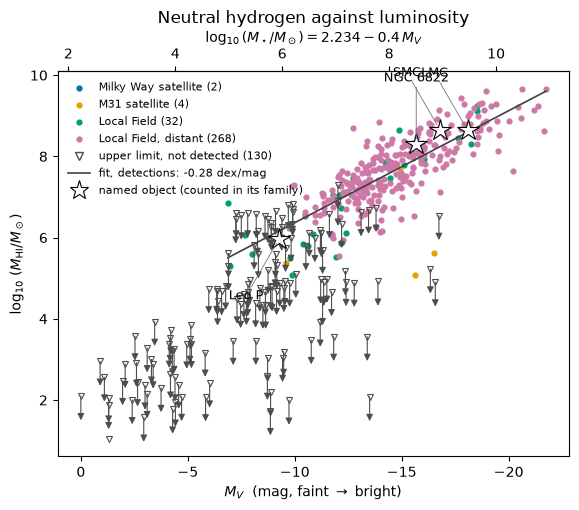

In [17]:
fig, ax = plt.subplots(figsize=(6.6, 5.0))
for family, colour in FAMILIES.items():
    s = detected[detected.family == family]
    if not s.empty:
        ax.scatter(s.M_V, s.mass_HI, s=12, color=colour, label=f"{family} ({len(s)})")
ax.plot([], [], marker="v", ms=6, ls="none", mfc="none", mec="0.3", label=f"upper limit, not detected ({len(limits)})")
for x, y in zip(limits.M_V, limits.mass_HI_ul):
    ax.plot(x, y, marker="v", ms=5, ls="none", mfc="none", mec="0.3", mew=0.8)
    ax.annotate("", xy=(x, y - 0.6), xytext=(x, y),
                arrowprops=dict(arrowstyle="-|>", color="0.3", lw=0.8, shrinkA=0, shrinkB=0))
xs = np.array([detected.M_V.min(), detected.M_V.max()])
ax.plot(xs, hi_fit.intercept + hi_fit.slope * xs, color="0.25", lw=1.2,
        label=f"fit, detections: {hi_fit.slope:.2f} dex/mag")
ax.invert_xaxis()
mark_anchors(ax, detected, "mass_HI")
ax.set_xlabel(r"$M_V$  (mag, faint $\rightarrow$ bright)")
ax.set_ylabel(r"$\log_{10}\,(M_{\rm HI}/M_\odot)$")
ax.set_title("Neutral hydrogen against luminosity")
mass_axis(ax)
ax.legend(fontsize=8, frameon=False)
plt.show()

Numbers; satellites against the rest.

In [18]:
# Numbers, then the split by environment: the satellites against everything else.
resid = detected.mass_HI - (hi_fit.intercept + hi_fit.slope * detected.M_V)
print(f"{len(detected)} detections and {len(limits)} upper limits: slope {hi_fit.slope:.3f} dex/mag,"
      f" scatter {resid.std(ddof=2):.3f} dex")
print(f"median log10(M_HI/M*) = {(detected.mass_HI - detected.mass_stellar).median():+.2f} dex")
env = np.where(dwarfs.family.isin(["Milky Way satellite", "M31 satellite"]), "Milky Way and M31 satellites", "everything else")
hi_rows = dwarfs.assign(environment=env)
hi_rows = hi_rows[hi_rows.mass_HI.notna() | hi_rows.mass_HI_ul.notna()]
by_env = hi_rows.assign(detected=hi_rows.mass_HI.notna()).groupby("environment").agg(rows=("key", "size"), detections=("detected", "sum"))
by_env["detected_fraction"] = (by_env.detections / by_env.rows).round(2)
print(by_env.to_string())
print(f"{limits.mass_HI_ul.lt(5).sum()} of the {len(limits)} limits are below 10**5 Msun, and"
      f" {limits.family.isin(['Milky Way satellite', 'M31 satellite']).sum()} of them are satellites")

306 detections and 130 upper limits: slope -0.276 dex/mag, scatter 0.557 dex
median log10(M_HI/M*) = -0.37 dex
                              rows  detections  detected_fraction
environment                                                      
Milky Way and M31 satellites    90           6               0.07
everything else                351         305               0.87
86 of the 130 limits are below 10**5 Msun, and 84 of them are satellites


The strongest single signal in the file: outside the Milky Way and M31 systems 87% of dwarfs with an H I
measurement are detected, inside them 7%, and 84 of the 130 limits belong to the two satellite families
(Putman et al. 2021). Detections follow a shallow relation, M_HI ∝ L^0.7, with a scatter of 0.56 dex, and
the median detected dwarf holds about 40% of its stellar mass in neutral hydrogen. Faint field dwarfs are
either gas-rich or gas-poor (Rey et al. 2022).

## 7. Halo 605 on the same axes

`Halo605_RT/output_00125`, measured with the methods of Adam's Test 3 (`Adam/Test/test3.ipynb`, py-noether).

Load the domains reaching inside 35 kpc, then centre on the stars as Test 3 does (`halo.center`).

In [19]:
import json
import warnings

import pynbody
import pynbody.analysis.angmom
import pynbody.analysis.halo
from utils.loading import load_halo, survey_file

HALO, OUTPUT, R_LOAD = "Halo605_RT", 125, 35.0
sim = load_halo(OUTPUT, radius_kpc=R_LOAD, halo=HALO)      # survey centre, domains within 35 kpc
pynbody.analysis.halo.center(sim.star)                      # Test 3 centring, on the stars
print(f"loaded {len(sim.star):,} stars, {len(sim.gas):,} gas cells, {len(sim.dm):,} DM particles")

loaded 15,989 stars, 5,265,007 gas cells, 4,402,680 DM particles


R200c from the dark matter alone (Test 3 §6).

In [20]:
h = float(sim.properties["h"])
RHO_C = 2.775e11 * h**2 / 1.0e9                              # critical density, Msol / kpc^3

r_dm = np.sqrt(np.sum(np.asarray(sim.dm["pos"]) ** 2, axis=1))
order = np.argsort(r_dm)
m_cum = np.cumsum(np.asarray(sim.dm["mass"].in_units("Msol"))[order])
rho_mean = m_cum / (4.0 / 3.0 * np.pi * r_dm[order] ** 3)
first = np.where(rho_mean < 200.0 * RHO_C)[0][0]
R200C, M200C = float(r_dm[order][first]), float(m_cum[first])

with open(survey_file(OUTPUT, "halo", HALO)) as f:
    survey_r200 = json.load(f)["R200c_kpc"]
print(f"R200c = {R200C:.3f} kpc, M200c = {M200C:.3e} Msol  (survey, all matter: {survey_r200:.2f} kpc)")

R200c = 31.317 kpc, M200c = 3.280e+09 Msol  (survey, all matter: 31.45 kpc)


Aperture: everything inside R200c.

In [21]:
R_STAR = np.sqrt(np.sum(np.asarray(sim.star["pos"]) ** 2, axis=1))
R_GAS = np.sqrt(np.sum(np.asarray(sim.gas["pos"]) ** 2, axis=1))
IN_STAR, IN_GAS = R_STAR < R200C, R_GAS < R200C
print(f"inside R200c: {IN_STAR.sum():,} stars, {IN_GAS.sum():,} gas cells")

inside R200c: 15,976 stars, 3,163,698 gas cells


Hydrogen (Test 3 §1.3): $X = 1 - Y - Z$, $Y = 0.24$, $Z = 2.09\,Y_{\rm O} + 1.06\,Y_{\rm Fe}$; $x_{\rm H_2} = \tfrac12(1 - x_{\rm HI} - x_{\rm HII})$.

In [22]:
Y_HE = 0.24
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="Conjoining derived and non-derived arrays*")
    M_GAS = np.asarray(sim.gas["mass"].in_units("Msol"))[IN_GAS]
Z_GAS = 2.09 * np.asarray(sim.gas["metal_O"])[IN_GAS] + 1.06 * np.asarray(sim.gas["metal_Fe"])[IN_GAS]
X_GAS = np.clip(1.0 - Y_HE - Z_GAS, 0.0, None)
M_H = X_GAS * M_GAS

x_HI = np.asarray(sim.gas["x_HI"])[IN_GAS]
x_H2 = 0.5 * (1.0 - x_HI - np.asarray(sim.gas["x_HII"])[IN_GAS])
M_HI, M_H2 = M_H * x_HI, M_H * x_H2                          # as Test 3 §1.3.2
print(f"M_gas = {M_GAS.sum():.3e}, M_HI = {M_HI.sum():.3e}, M_H2 = {M_H2.sum():.3e} Msol")

M_gas = 3.366e+07, M_HI = 5.224e+04, M_H2 = 2.312e+00 Msol


V band: Test 3's `metals` alias, so pynbody can compute `V_mag`.

In [23]:
if "metals" not in sim.star.keys():
    sim.star["metals"] = 2.09 * np.asarray(sim.star["metal_O"]) + 1.06 * np.asarray(sim.star["metal_Fe"])

M_STAR_P = np.asarray(sim.star["mass"].in_units("Msol"))[IN_STAR]
L_V = 10.0 ** (-0.4 * np.asarray(sim.star["V_mag"])[IN_STAR])
L_V[~np.isfinite(L_V)] = 0.0
M_V = -2.5 * np.log10(L_V.sum())
M_STAR = M_STAR_P.sum()
print(f"M_V = {M_V:.2f} mag, M_star = {M_STAR:.3e} Msol "
      f"(file's conversion: log M* = {MASS_OFFSET - 0.4 * M_V:.3f}, measured {np.log10(M_STAR):.3f})")

M_V = -10.58 mag, M_star = 2.871e+06 Msol (file's conversion: log M* = 6.465, measured 6.458)


[Fe/H], mass-weighted, solar reference of Asplund et al. 2009 (Test 3 §10).

In [24]:
FE_STAR = np.asarray(sim.star["metal_Fe"])[IN_STAR]
Z_STAR = 2.09 * np.asarray(sim.star["metal_O"])[IN_STAR] + 1.06 * FE_STAR
X_STAR = np.clip(1.0 - Y_HE - Z_STAR, 1e-3, None)
FE_H = np.log10(np.clip(FE_STAR / X_STAR, 1e-30, None)) - np.log10(1.32e-3 / 0.7381)
FE_H_HALO = float(np.average(FE_H, weights=M_STAR_P))
print(f"[Fe/H] = {FE_H_HALO:.3f} dex; {int((FE_STAR <= 0).sum())} stars with no iron sit on the 1e-30 floor")

[Fe/H] = -1.488 dex; 14 stars with no iron sit on the 1e-30 floor


12 + log(O/H) of the gas (Test 3 §10).

In [25]:
O_H = np.asarray(sim.gas["metal_O"])[IN_GAS] / np.where(X_GAS > 0, X_GAS, np.nan)
LOG_OH = 12.0 + np.log10(np.clip(O_H, 1e-30, None)) + np.log10(1.00794 / 15.9994)
ok = np.isfinite(LOG_OH) & (np.asarray(sim.gas["metal_O"])[IN_GAS] > 0)
LOG_OH_HALO = float(np.average(LOG_OH[ok], weights=M_GAS[ok]))
print(f"12 + log(O/H) = {LOG_OH_HALO:.3f} (gas, mass-weighted)")

12 + log(O/H) = 7.249 (gas, mass-weighted)


Half-light radius: 3D as in Test 3 §8, and face-on projected, which is what the file quotes.

In [26]:
def r_enclosing(radius, weights, fraction):
    """Radius enclosing `fraction` of the total weight."""
    order = np.argsort(radius)
    cumulative = np.cumsum(weights[order])
    return float(np.interp(fraction * cumulative[-1], cumulative, radius[order]))


R_HALF_3D = r_enclosing(R_STAR[IN_STAR], L_V, 0.5)
pynbody.analysis.angmom.faceon(sim)
POS_2D = np.asarray(sim.star["pos"])[IN_STAR]
R_HALF_2D = r_enclosing(np.hypot(POS_2D[:, 0], POS_2D[:, 1]), L_V, 0.5)
print(f"R_half = {R_HALF_2D * 1000:.0f} pc projected, {R_HALF_3D * 1000:.0f} pc 3D")

R_half = 199 pc projected, 344 pc 3D


Stellar velocity dispersion and SFR over the last 100 Myr (Test 3 §11–12).

In [27]:
VEL = np.asarray(sim.star["vel"])[IN_STAR]
V_RES = VEL - np.average(VEL, axis=0, weights=M_STAR_P)
SIGMA_STAR = float(np.sqrt(np.average(np.sum(V_RES**2, axis=1), weights=M_STAR_P) / 3.0))   # 1D

AGE = np.asarray(sim.star["age"].in_units("Gyr"))[IN_STAR]
SFR_100 = M_STAR_P[AGE < 0.1].sum() / 1.0e8                  # Msol / yr
print(f"sigma_star (1D) = {SIGMA_STAR:.2f} km/s; SFR(100 Myr) = {SFR_100:.3e} Msol/yr")

sigma_star (1D) = 8.89 km/s; SFR(100 Myr) = 0.000e+00 Msol/yr


Halo 605 in the file's columns.

In [28]:
halo605 = pd.Series({
    "M_V": M_V, "mass_stellar": np.log10(M_STAR), "metallicity": FE_H_HALO,
    "rhalf_sph_physical": R_HALF_2D * 1000, "mass_HI": np.log10(M_HI.sum()), "vlos_sigma": SIGMA_STAR,
}, name="Halo 605")
extra = pd.Series({"R200c_kpc": R200C, "M200c": M200C, "R_half_3D_pc": R_HALF_3D * 1000,
                   "M_H2": M_H2.sum(), "12+log(O/H)": LOG_OH_HALO, "SFR_100Myr": SFR_100}, name="Halo 605")
print(halo605.round(3).to_string()); print(); print(extra.to_string())

M_V                   -10.578
mass_stellar            6.458
metallicity            -1.488
rhalf_sph_physical    199.496
mass_HI                 4.718
vlos_sigma              8.891

R200c_kpc       3.131736e+01
M200c           3.279532e+09
R_half_3D_pc    3.438637e+02
M_H2            2.311970e+00
12+log(O/H)     7.249485e+00
SFR_100Myr      0.000000e+00


Against the file's fits at this luminosity.

In [29]:
print(f"{'':20s}{'Halo 605':>12s}{'file fit':>12s}")
print(f"{'M_V [mag]':20s}{M_V:>12.2f}{'':>12s}")
print(f"{'[Fe/H] [dex]':20s}{FE_H_HALO:>12.2f}{fit.intercept + fit.slope * M_V:>12.2f}")
print(f"{'R_half [pc]':20s}{R_HALF_2D * 1000:>12.0f}{10 ** (size_fit.intercept + size_fit.slope * M_V):>12.0f}")
print(f"{'log M_HI [Msol]':20s}{np.log10(M_HI.sum()):>12.2f}{hi_fit.intercept + hi_fit.slope * M_V:>12.2f}")
near = dwarfs[(dwarfs.M_V - M_V).abs() < 1.0].vlos_sigma.dropna()
print(f"{'sigma* [km/s]':20s}{SIGMA_STAR:>12.2f}{near.median():>12.2f}   (file: median of {len(near)} dwarfs within 1 mag)")

                        Halo 605    file fit
M_V [mag]                 -10.58            
[Fe/H] [dex]               -1.49       -1.62
R_half [pc]                  199         337
log M_HI [Msol]             4.72        6.53
sigma* [km/s]               8.89        9.20   (file: median of 17 dwarfs within 1 mag)


The four relations with Halo 605 on them. M_HI is plotted as log10, like the file's column.

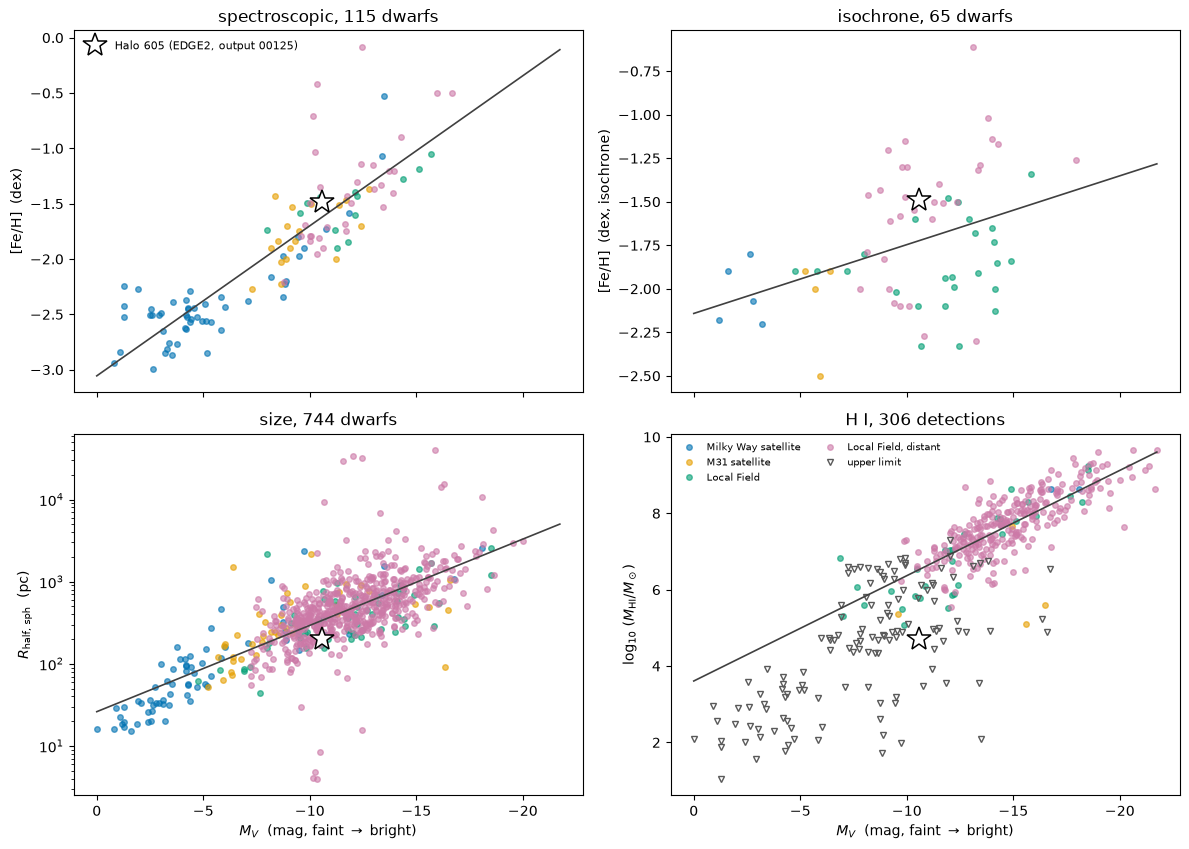

In [30]:
# The four relations with Halo 605 on them. Points and lines are the file; the star is the simulation.
fig, axes = plt.subplots(2, 2, figsize=(12.0, 8.6), sharex=True)
(ax_spec, ax_iso), (ax_size, ax_hi) = axes
axes[0, 0].invert_xaxis()                   # x is shared: invert it once, not four times
halo = dict(marker="*", ms=18, mfc="white", mec="black", mew=1.1, ls="none", zorder=6)

for family, colour in FAMILIES.items():
    s = spec[spec.family == family]
    ax_spec.plot(s.M_V, s.metallicity_spectroscopic, marker="o", ms=4, ls="none", color=colour, alpha=0.6)
    s = iso[iso.family == family]
    ax_iso.plot(s.M_V, s.metallicity_isochrone, marker="o", ms=4, ls="none", color=colour, alpha=0.6)
    s = size[size.family == family]
    ax_size.plot(s.M_V, s.rhalf_sph_physical, marker="o", ms=4, ls="none", color=colour, alpha=0.6)
    s = detected[detected.family == family]
    ax_hi.plot(s.M_V, s.mass_HI, marker="o", ms=4, ls="none", color=colour, alpha=0.6, label=family)

ax_hi.plot(limits.M_V, limits.mass_HI_ul, marker="v", ms=5, ls="none", mfc="none", mec="0.35", label="upper limit")

for ax, ycol, f in [(ax_spec, "metallicity_spectroscopic", fit), (ax_iso, "metallicity_isochrone", iso_fit),
                    (ax_size, None, size_fit), (ax_hi, "mass_HI", hi_fit)]:
    xs = np.array([dwarfs.M_V.min(), dwarfs.M_V.max()])
    if ax is ax_size:
        ax.plot(xs, 10 ** (f.intercept + f.slope * xs), color="0.25", lw=1.2)
        ax.set_yscale("log")
    else:
        ax.plot(xs, f.intercept + f.slope * xs, color="0.25", lw=1.2)

ax_spec.plot(M_V, FE_H_HALO, **halo)
ax_iso.plot(M_V, FE_H_HALO, **halo)
ax_size.plot(M_V, R_HALF_2D * 1000, **halo)
ax_hi.plot(M_V, np.log10(M_HI.sum()), **halo)

ax_spec.set_ylabel(r"[Fe/H]  (dex)")
ax_iso.set_ylabel(r"[Fe/H]  (dex, isochrone)")
ax_size.set_ylabel(r"$R_{\rm half,\,sph}$  (pc)")
ax_hi.set_ylabel(r"$\log_{10}\,(M_{\rm HI}/M_\odot)$")
for ax, title in [(ax_spec, f"spectroscopic, {len(spec)} dwarfs"), (ax_iso, f"isochrone, {len(iso)} dwarfs"),
                  (ax_size, f"size, {len(size)} dwarfs"), (ax_hi, f"H I, {len(detected)} detections")]:
    ax.set_title(title)
for ax in (ax_size, ax_hi):
    ax.set_xlabel(r"$M_V$  (mag, faint $\rightarrow$ bright)")
ax_hi.legend(fontsize=7, frameon=False, ncol=2)
ax_spec.plot([], [], **halo, label="Halo 605 (EDGE2, output 00125)")
ax_spec.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.show()